# Лабораторная работа № 3. Метрические методы классификации
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** изучение принципов построения информационных систем с использованием метрических методов классификации.

**Основные задачи (из методички):**
- изучение инструментария Python для реализации алгоритмов метрической классификации;
- изучение методов оптимизации параметров метрической классификации;
- освоение модификаций kNN-метода.

**Данные:** Iris для учебного примера; прежний сценарий RCAEval RE2-OB для индивидуального задания.


## 1. Локальный запуск и краткие сведения
Используем окружение Conda `rcaeval-ai`, как в прошлых работах. 

**kNN** определяет класс нового объекта по K наиболее похожим объектам из обучающих данных. При K = 1 используется один ближайший сосед, при большем K - нескольких соседей.

**Hold-out** - один раз разделить данные на обучение и проверку. **Cross validation (CV)** - разделить данные на несколько частей, по очереди проверять на каждой части и усреднить результат. **Accuracy** - доля правильных ответов.

Подключаем библиотеки.

In [1]:
from pathlib import Path
from importlib.metadata import version
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, balanced_accuracy_score

Задаём пути к данным и результатам.

In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab03'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
K_VALUES = list(range(1, 50))
FOLDS = [3, 5, 10]
sns.set_theme(style='whitegrid')

Выводим и сохраняем версии библиотек.

In [3]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'seaborn', 'scikit-learn', 'pyarrow']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
seaborn          0.13.2
scikit-learn      1.7.2
pyarrow          21.0.0
Name: Версия, dtype: object

165

Определяем функцию для сохранения и показа графиков.

In [4]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 1.1. Масштаб признаков
У RCAEval память измеряется большими числами, а задержка — долями единицы. Без подготовки память почти полностью определяла бы расстояние между строками. `StandardScaler` приводит каждый признак к сопоставимому масштабу: вычитает среднее и делит на стандартное отклонение.

Объединяем эту подготовку и kNN в `Pipeline`. Средние и разброс считаются только по обучающим строкам — отдельно при каждом разделении. Проверочные строки не участвуют в подготовке модели.

Определяем функцию создания kNN с подготовкой признаков.

In [5]:
def make_knn(k, weights='uniform', p=2):
    return make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k, weights=weights, p=p, n_jobs=1)
    )

### 1.2. Функции для сравнения параметров
Одинаково оцениваем каждое K. Для hold-out используем доли проверки 20%, 30% и 50%, то есть доли обучения 80%, 70% и 50%. При каждом K разделение одинаковое: сравниваем модели на одних и тех же строках.

Определяем функцию расчёта hold-out для разных K и долей данных.

In [6]:
def holdout_table(X, y):
    rows = []
    for test_size in [0.2, 0.3, 0.5]:
        X_train, X_valid, y_train, y_valid = train_test_split(
            X, y, test_size=test_size, stratify=y, random_state=SEED)
        for k in K_VALUES:
            model = make_knn(k).fit(X_train, y_train)
            accuracy = accuracy_score(y_valid, model.predict(X_valid))
            rows.append({'K': k, 'train_share': 1 - test_size, 'test_share': test_size,
                         'train_rows': len(X_train), 'validation_rows': len(X_valid),
                         'accuracy': accuracy})
    return pd.DataFrame(rows)

При CV сравниваем 3, 5 и 10 частей. Для Iris сохраняем доли видов в каждой части. Для RCAEval дополнительно сохраняем минутные участки целиком: записи одного участка не попадают одновременно в обучение и проверку. Столбец `std` показывает, насколько отличаются результаты отдельных частей.

Определяем функцию перекрёстной проверки для разных K и числа частей.

In [7]:
def cv_table(X, y, groups=None):
    rows = []
    for fold in FOLDS:
        cv = (StratifiedKFold(n_splits=fold, shuffle=True, random_state=SEED)
              if groups is None else
              StratifiedGroupKFold(n_splits=fold, shuffle=True, random_state=SEED))
        for k in K_VALUES:
            scores = cross_val_score(make_knn(k), X, y, groups=groups,
                                     cv=cv, scoring='accuracy', n_jobs=1)
            rows.append({'fold': fold, 'K': k, 'accuracy': scores.mean(),
                         'error': 1 - scores.mean(), 'std': scores.std()})
    return pd.DataFrame(rows)

## 2. Учебная задача: ирисы Фишера
Повторяем пример методички: загрузка через pandas, парные графики, kNN с K = 3, изменение введённых признаков, hold-out и подбор K по CV.

Одна строка — один цветок. Четыре признака — длина и ширина чашелистика и лепестка, в сантиметрах. Ответ — один из трёх видов: `Iris-setosa`, `Iris-versicolor`, `Iris-virginica`.

### 2.1. Загрузка и названия столбцов

Читаем файл с настройками pandas по умолчанию, как в первом шаге примера.

In [8]:
iris_path = ROOT / 'data/raw/iris/iris.data'
iris_with_header = pd.read_csv(iris_path)

Показываем, почему первая строка данных стала заголовком.

In [9]:
display(iris_with_header.head())
print('Строк при таком чтении:', len(iris_with_header))

,5.1,3.5,1.4,0.2,Iris-setosa
0,4.9,3.0,1.4,0.2,Iris-setosa
1,4.7,3.2,1.3,0.2,Iris-setosa
2,4.6,3.1,1.5,0.2,Iris-setosa
3,5.0,3.6,1.4,0.2,Iris-setosa
4,5.4,3.9,1.7,0.4,Iris-setosa


Строк при таком чтении: 149


В файле нет заголовка. pandas принял первый цветок за названия столбцов, поэтому осталось 149 строк вместо 150. Исправляем чтение.

Читаем файл без заголовка.

In [10]:
iris_numbered = pd.read_csv(iris_path, header=None)

Показываем таблицу с номерами столбцов.

In [11]:
display(iris_numbered.head())
print('Строк:', len(iris_numbered))

,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


Строк: 150


Загружаем Iris с понятными названиями столбцов.

In [12]:
iris_features = ['sepal length', 'sepal width', 'petal length', 'petal width']
iris = pd.read_csv(iris_path, header=None, names=iris_features + ['answer'])

Печатаем первые строки и число цветков каждого вида.

In [13]:
display(iris.head())
display(iris['answer'].value_counts().rename('Цветков'))

,sepal length,sepal width,petal length,petal width,answer
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


answer
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: Цветков, dtype: int64

### 2.2. Парные графики
Сначала рассматриваем все цветки вместе, затем отмечаем виды разными цветами и маркерами. На диагонали находятся гистограммы отдельных признаков; остальные панели сравнивают пары размеров.

Строим парные графики без разделения на виды.

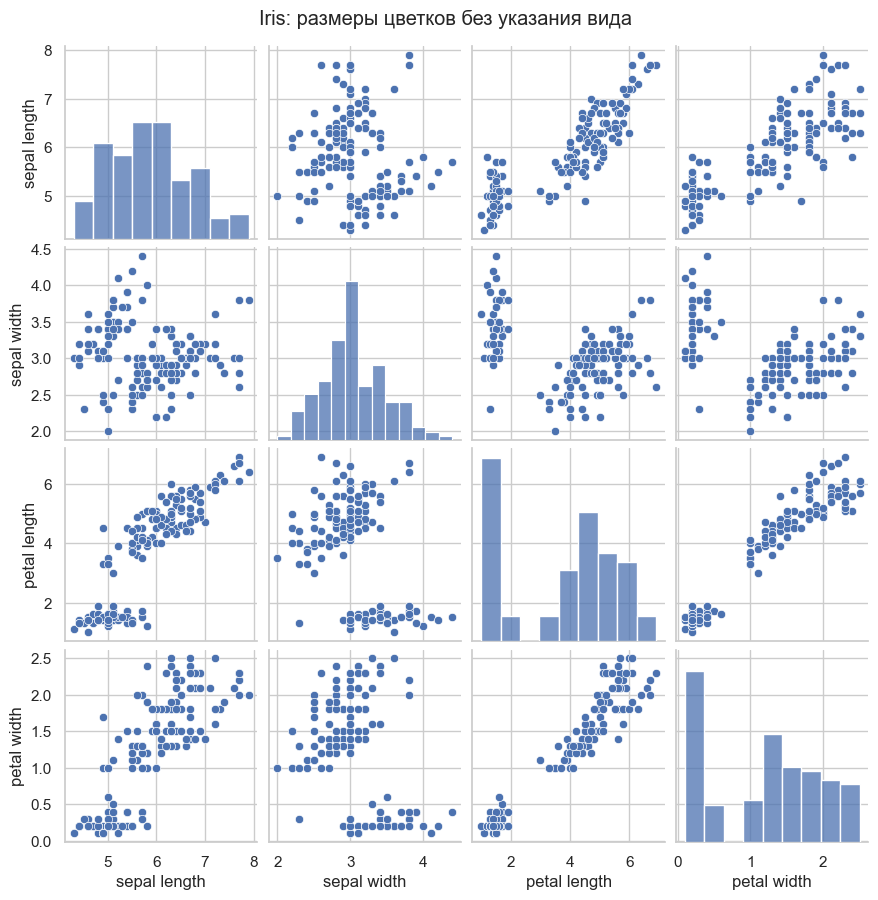

In [14]:
grid = sns.pairplot(iris, vars=iris_features, diag_kind='hist', height=2.2)
grid.figure.suptitle('Iris: размеры цветков без указания вида', y=1.02)
save_show(grid.figure, '01_iris_pairplot.png')

Каждая точка на парной панели это цветок. Уже без подписей видны группы: например, часть цветков имеет заметно более короткие лепестки. Гистограммы на диагонали показывают, какие размеры встречаются чаще.

Строим парные графики с цветом и маркером вида.

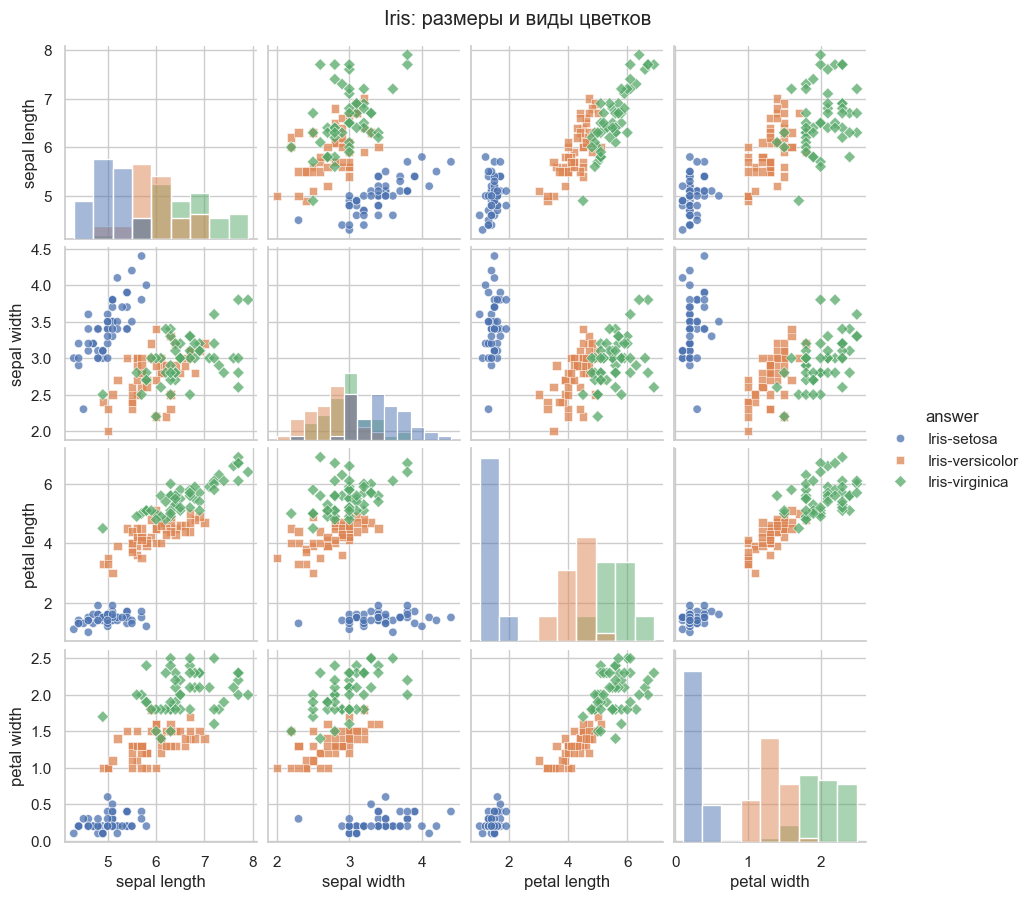

In [15]:
iris_order = ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
grid = sns.pairplot(iris, vars=iris_features, hue='answer', hue_order=iris_order,
                    markers=['o', 's', 'D'], diag_kind='hist', height=2.2,
                    plot_kws={'alpha': 0.75}, diag_kws={'common_norm': False})
grid.figure.suptitle('Iris: размеры и виды цветков', y=1.02)
save_show(grid.figure, '02_iris_pairplot_classes.png')

Setosa хорошо отделяется по длине и ширине лепестка. Versicolor и virginica местами перекрываются: похожие размеры могут принадлежать разным видам. Поэтому классификатор не обязан правильно определять каждый цветок.

### 2.3. Обучение и новые объекты
Откладываем 20% цветков для итоговой проверки. Остальные используем для обучения и выбора K. `stratify` сохраняет доли трёх видов.

Разделяем Iris на данные для подбора параметров и отдельную итоговую проверку.

In [16]:
X_iris = iris[iris_features]
y_iris = iris['answer']
Xi_dev, Xi_test, yi_dev, yi_test = train_test_split(
    X_iris, y_iris, test_size=0.2, stratify=y_iris, random_state=SEED)
print('Для обучения и подбора:', len(Xi_dev), '| Для итоговой проверки:', len(Xi_test))

Для обучения и подбора: 120 | Для итоговой проверки: 30


Обучаем обычный kNN с K = 3, как в примере методички.

In [17]:
iris_example = KNeighborsClassifier(n_neighbors=3)
iris_example.fit(Xi_dev, yi_dev)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


Ниже первая строка взята из примера методички. Следующие строки это введённые вручную размеры, чтобы увидеть изменение ответа. 

Вводим новые размеры и получаем виды цветков.

In [18]:
new_iris = pd.DataFrame([
    [1.2, 1.0, 2.8, 1.2],
    [5.12, 3.53, 1.42, 0.21],
    [6.02, 2.83, 4.32, 1.31],
    [6.52, 3.03, 5.42, 2.11]
], columns=iris_features)
display(new_iris.assign(Предсказание=iris_example.predict(new_iris)))

,sepal length,sepal width,petal length,petal width,Предсказание
0,1.20,1.00,2.80,1.20,Iris-versicolor
1,5.12,3.53,1.42,0.21,Iris-setosa
2,6.02,2.83,4.32,1.31,Iris-versicolor
3,6.52,3.03,5.42,2.11,Iris-virginica


### 2.4. Оценка hold-out
Для сравнения K дополнительно делим только `Xi_dev`. Итоговые 30 цветков пока не используем. С этого шага включаем `StandardScaler`, чтобы сравнивать признаки в одном масштабе.

Вычисляем hold-out для K от 1 до 49 и трёх долей проверки.

In [19]:
iris_holdout = holdout_table(Xi_dev, yi_dev)
iris_holdout.to_csv(REPORT / 'iris_holdout.csv', index=False)

Печатаем таблицу точности для разных K и долей проверки.

In [20]:
display(iris_holdout.pivot(index='K', columns='test_share', values='accuracy').round(3))

test_share,0.2,0.3,0.5
K,,,
1,0.958,0.944,0.950
2,0.958,0.944,0.933
3,0.917,0.917,0.950
4,0.958,0.917,0.933
5,0.917,0.917,0.950
6,0.917,1.000,0.950
7,0.917,0.944,0.950
8,1.000,0.944,0.950
9,0.958,0.917,0.967


Строим график точности Iris при разных K.

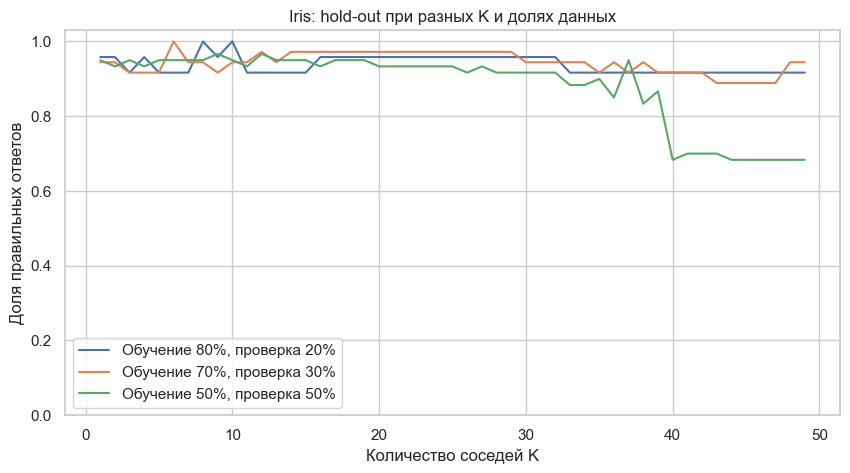

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
for share, part in iris_holdout.groupby('test_share'):
    ax.plot(part['K'], part['accuracy'], label=f'Обучение {1-share:.0%}, проверка {share:.0%}')
ax.set(title='Iris: hold-out при разных K и долях данных',
       xlabel='Количество соседей K', ylabel='Доля правильных ответов', ylim=(0, 1.03))
ax.legend()
save_show(fig, '03_iris_holdout.png')

По горизонтали указано K, по вертикали доля правильных ответов. Каждая линия соответствует своему разделению данных. При большом K модель учитывает много цветков, в том числе других видов, и может чаще ошибаться. Один случайный hold-out не даёт окончательного ответа о лучшем K.

### 2.5. Перекрёстная проверка и выбор K
Проверяем K от 1 до 49 при 3, 5 и 10 частях. Заранее выбираем **5 частей** как основной способ подбора. Лучшее K — значение с наибольшей средней accuracy при этой проверке. При одинаковом результате берём меньшее K: для такого качества достаточно меньшего числа соседей. Это правило используем и для RCAEval.

Вычисляем CV на Iris.

In [22]:
iris_cv = cv_table(Xi_dev, yi_dev)
iris_cv.to_csv(REPORT / 'iris_cv.csv', index=False)

Показываем точность при разных K и числе частей.

In [23]:
display(iris_cv.pivot(index='K', columns='fold', values='accuracy').round(3))

fold,3,5,10
K,,,
1,0.933,0.925,0.925
2,0.933,0.917,0.925
3,0.942,0.925,0.933
4,0.942,0.933,0.925
5,0.958,0.942,0.933
6,0.958,0.967,0.942
7,0.950,0.950,0.950
8,0.942,0.950,0.967
9,0.942,0.942,0.942


Строим график ошибки CV на Iris.

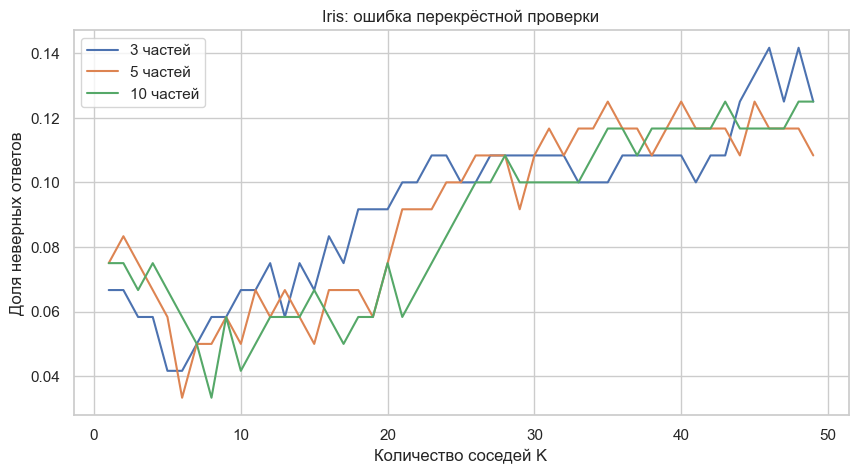

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
for fold, part in iris_cv.groupby('fold'):
    ax.plot(part['K'], part['error'], label=f'{fold} частей')
ax.set(title='Iris: ошибка перекрёстной проверки',
       xlabel='Количество соседей K', ylabel='Доля неверных ответов')
ax.legend()
save_show(fig, '04_iris_cv_error.png')

Чем ниже линия, тем меньше ошибок. Разные числа частей могут дать разные лучшие K, потому что состав обучающих и проверочных строк меняется. Подбираем K по заранее выбранной линии для 5 частей, а не по итоговой проверке.

На этом рисунке при небольших K ошибка ниже, чем при больших K. Для пяти частей наименьшая ошибка получилась при K = 6. Это значение далее проверяется на отложенных цветках.

Находим все лучшие K для каждого числа частей и выбираем итоговое K для Iris.

In [25]:
for fold, part in iris_cv.groupby('fold'):
    best = part.loc[part['accuracy'] == part['accuracy'].max(), 'K'].tolist()
    print(f'{fold} частей: лучшие K = {best}, accuracy = {part.accuracy.max():.3f}')
iris_primary = iris_cv.query('fold == 5')
iris_best_values = iris_primary.loc[iris_primary.accuracy == iris_primary.accuracy.max(), 'K'].tolist()
iris_best_k = min(iris_best_values)
print('Выбрано K =', iris_best_k)

3 частей: лучшие K = [5, 6], accuracy = 0.958
5 частей: лучшие K = [6], accuracy = 0.967
10 частей: лучшие K = [8], accuracy = 0.967
Выбрано K = 6


Обучаем выбранную модель и проверяем её на отложенных цветках.

In [26]:
iris_model = make_knn(iris_best_k).fit(Xi_dev, yi_dev)
iris_prediction = iris_model.predict(Xi_test)
iris_accuracy = accuracy_score(yi_test, iris_prediction)
iris_errors = int((iris_prediction != yi_test).sum())
print(f'Итоговая accuracy: {iris_accuracy:.3f} ({iris_accuracy:.1%})')
print(f'Ошибок: {iris_errors} из {len(yi_test)}')

Итоговая accuracy: 0.967 (96.7%)
Ошибок: 1 из 30


Показываем, какие виды модель перепутала.

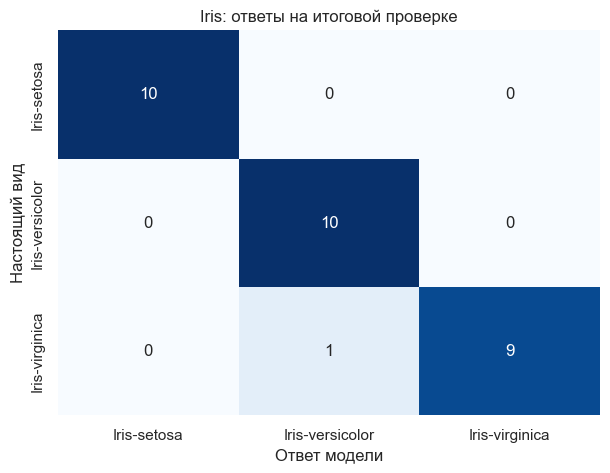

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(confusion_matrix(yi_test, iris_prediction, labels=iris_order), annot=True,
            fmt='d', cmap='Blues', cbar=False, xticklabels=iris_order,
            yticklabels=iris_order, ax=ax)
ax.set(title='Iris: ответы на итоговой проверке', xlabel='Ответ модели', ylabel='Настоящий вид')
save_show(fig, '05_iris_confusion.png')

Строка соответствует настоящему виду, столбец — ответу модели. Числа на диагонали — правильные ответы; числа вне диагонали — ошибки. Так видно не только общее качество, но и то, какие виды оказались похожими для kNN.

В полученном результате все 10 цветков setosa и все 10 versicolor определены верно. Один цветок virginica модель отнесла к versicolor. Всего верно определено 29 из 30 цветков.

### 2.6. Как выглядит решение на графике
Для наглядности строим **отдельную модель только по двум признакам лепестка**. Она обучается на тех же обучающих цветках с выбранным K. Основной результат выше рассчитан по четырём признакам. Цвет фона на следующем рисунке показывает ответ двухпризнаковой модели для новых сочетаний размеров.

Обучаем модель по двум размерам лепестка.

In [28]:
iris_plot_features = ['petal length', 'petal width']
iris_plot_model = make_knn(iris_best_k).fit(Xi_dev[iris_plot_features], yi_dev)

Строим области решений и отмечаем цветки итоговой проверки.

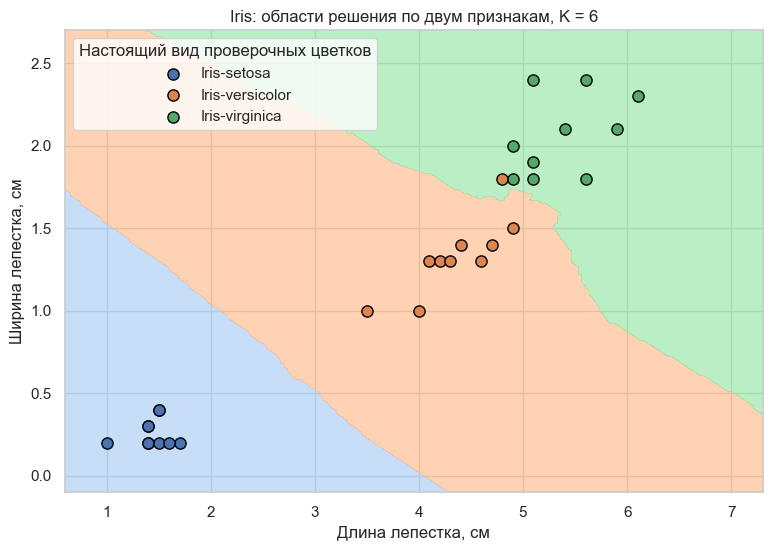

In [29]:
x = np.linspace(X_iris['petal length'].min() - 0.4, X_iris['petal length'].max() + 0.4, 200)
y = np.linspace(X_iris['petal width'].min() - 0.2, X_iris['petal width'].max() + 0.2, 200)
xx, yy = np.meshgrid(x, y)
grid_points = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=iris_plot_features)
regions = pd.Series(iris_plot_model.predict(grid_points)).map(dict(zip(iris_order, range(3))))
fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(xx, yy, regions.to_numpy().reshape(xx.shape), levels=[-0.5, 0.5, 1.5, 2.5],
            cmap=ListedColormap(sns.color_palette('pastel', 3)), alpha=0.6)
for label, color in zip(iris_order, sns.color_palette('deep', 3)):
    points = Xi_test.loc[yi_test == label]
    ax.scatter(points['petal length'], points['petal width'], color=color,
               edgecolor='black', s=65, label=label)
ax.set(title=f'Iris: области решения по двум признакам, K = {iris_best_k}',
       xlabel='Длина лепестка, см', ylabel='Ширина лепестка, см')
ax.legend(title='Настоящий вид проверочных цветков')
save_show(fig, '06_iris_decision_regions.png')

Точка показывает проверочный цветок, её цвет — настоящий вид. Фон показывает ответ отдельной модели по двум размерам. Если цвета точки и области относятся к разным видам, эта модель ошиблась. Границы отделяют сочетания размеров с разными ответами; за пределами наблюдавшихся размеров фон является лишь продолжением правила модели.

## 3. Индивидуальное задание: RCAEval
### 3.1. Датасет и задача классификации
Используем тот же **RCAEval RE2-OB (Online Boutique)**, что в работах № 1 и № 2. Это сохранённые измерения микросервисов во время эксперимента с CPU stress.

Класс задаём по известному времени внесения сбоя: **0 — до внесения, 1 — начиная с внесения**. По четырём метрикам модель должна определить, к какому периоду относится новая для неё строка. Время и метку периода не включаем в признаки.

Такая задача позволяет изучить kNN на прежних данных. Метка «после» не означает, что каждая строка отдельно подтверждена как неисправная. В этом одном сценарии нельзя обучить различение разных типов сбоев или оценить работу на других сервисах.


Читаем сохранённое имя сценария из первой работы.

In [30]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case
print('Сценарий:', case)

Сценарий: re2ob_checkoutservice_cpu_1


Загружаем локальные метрики и время внесения сбоя.

In [31]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Печатаем первые строки и сведения о сценарии.

In [32]:
display(df.head())
print('Строк:', len(df), '| Метрик:', df.shape[1] - 1)
print('Сервис:', selection['root_cause_service'], '| Тип сбоя:', selection['fault'])
print('Внесение сбоя:', pd.to_datetime(inject_time, unit='s', utc=True))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Строк: 1441 | Метрик: 72
Сервис: checkoutservice | Тип сбоя: cpu
Внесение сбоя: 2024-01-15 21:36:06+00:00


Выбираем четыре числовых признака и создаём метки периодов.

In [33]:
rca_features = ['checkoutservice_cpu', 'checkoutservice_mem',
                'checkoutservice_latency-50', 'checkoutservice_socket']
X_rca = df[rca_features].copy()
y_rca = (df['time'] >= inject_time).astype(int)
rca_labels = ['До внесения', 'После внесения']

Показываем назначение признаков, пропуски и число строк в классах.

In [34]:
display(pd.DataFrame({
    'Признак': rca_features,
    'Описание': ['Показатель CPU', 'Память', 'Медианная задержка', 'Показатель socket'],
    'Тип': X_rca.dtypes.to_numpy(),
    'Пропуски': X_rca.isna().sum().to_numpy()
}))
display(y_rca.map(dict(enumerate(rca_labels))).value_counts().rename('Строк'))

,Признак,Описание,Тип,Пропуски
0,checkoutservice_cpu,Показатель CPU,float64,0
1,checkoutservice_mem,Память,float64,0
2,checkoutservice_latency-50,Медианная задержка,float64,0
3,checkoutservice_socket,Показатель socket,float64,0


time
После внесения    721
До внесения       720
Name: Строк, dtype: int64

Выбрано четыре числовых признака, как рекомендует методичка. В них нет пропусков, поэтому строки не удаляем и значения не заполняем. Используем исходные значения: точные единицы отдельных метрик в сохранённом файле не указаны. Для расстояний масштаб каждого признака подготовит `StandardScaler`.

### 3.2. Данные для подбора и итоговой проверки
RCAEval содержит последовательные измерения одного эксперимента. Близкие по времени строки могут быть очень похожими. Разбиваем запись на минутные участки и оставляем целые участки для итоговой проверки. Остальные участки используются для выбора K.

Это помогает уменьшить смешивание соседних записей, но не делает проверку независимым новым экспериментом. По времени не прогнозируем будущее: в обеих подвыборках представлены оба периода.

Создаём минутные группы и откладываем одну из пяти частей для итоговой проверки.

In [35]:
minute_groups = ((df['time'] - df['time'].min()) // 60).astype(int)
rca_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
rca_dev_idx, rca_test_idx = next(rca_split.split(X_rca, y_rca, groups=minute_groups))
Xr_dev, Xr_test = X_rca.iloc[rca_dev_idx], X_rca.iloc[rca_test_idx]
yr_dev, yr_test = y_rca.iloc[rca_dev_idx], y_rca.iloc[rca_test_idx]
gr_dev = minute_groups.iloc[rca_dev_idx]

Показываем размеры подвыборок и число строк каждого периода.

In [36]:
display(pd.DataFrame({
    'Для подбора': yr_dev.value_counts().sort_index(),
    'Итоговая проверка': yr_test.value_counts().sort_index()
}).rename(index=dict(enumerate(rca_labels))))
print(f'Для подбора: {len(Xr_dev)} строк ({len(Xr_dev)/len(df):.1%})')
print(f'Итоговая проверка: {len(Xr_test)} строк ({len(Xr_test)/len(df):.1%})')
print('Минутных участков для подбора:', gr_dev.nunique())

,Для подбора,Итоговая проверка
time,,
До внесения,540,180
После внесения,601,120


Для подбора: 1141 строк (79.2%)
Итоговая проверка: 300 строк (20.8%)
Минутных участков для подбора: 20


### 3.3. Классификатор с K, заданным пользователем — пункт 2.1
Чтобы изменить число соседей, меняем `K_USER` и повторно выполняем ячейки этого подраздела. Начальное значение — 3. Для текущей подвыборки число соседей должно быть от 1 до размера обучающей части.

Проверяем этот первый классификатор на небольшой внутренней подвыборке. Отложенные минутные участки пока не используем.

Задаём K и обучаем классификатор.

In [37]:
K_USER = 3
Xu_train, Xu_valid, yu_train, yu_valid = train_test_split(
    Xr_dev, yr_dev, test_size=0.3, stratify=yr_dev, random_state=SEED)
user_model = make_knn(K_USER).fit(Xu_train, yu_train)

Показываем ответы для первых проверочных строк и долю правильных ответов.

In [38]:
user_prediction = user_model.predict(Xu_valid)
user_accuracy = accuracy_score(yu_valid, user_prediction)
user_demo = Xu_valid.head().copy()
user_demo['Настоящий период'] = yu_valid.head().map(dict(enumerate(rca_labels)))
user_demo['Ответ модели'] = pd.Series(user_prediction[:5], index=user_demo.index).map(dict(enumerate(rca_labels)))
display(user_demo)
print(f'K = {K_USER}, hold-out accuracy = {user_accuracy:.3f} ({user_accuracy:.1%})')

,checkoutservice_cpu,checkoutservice_mem,checkoutservice_latency-50,checkoutservice_socket,Настоящий период,Ответ модели
1231,19.985160,16326656.0,0.321427,11.0,После внесения,После внесения
671,0.487225,11649024.0,0.312500,9.0,До внесения,До внесения
1199,20.003765,16207872.0,0.316667,11.0,После внесения,После внесения
81,0.340919,11796480.0,0.350000,9.0,До внесения,До внесения
543,0.393612,11907072.0,0.229000,9.0,До внесения,До внесения


K = 3, hold-out accuracy = 1.000 (100.0%)


### 3.4. Hold-out при разных K и долях — пункт 2.2
Сравниваем K от 1 до 49. Для данных подбора используем три варианта: 80/20, 70/30 и 50/50. Здесь разделение выполняется случайно по строкам, как в учебном примере. Поэтому похожие соседние измерения могут попасть в разные части и повысить оценку. Для выбора K далее используем CV по целым минутным участкам.

Вычисляем hold-out для RCAEval.

In [39]:
rca_holdout = holdout_table(Xr_dev, yr_dev)
rca_holdout.to_csv(REPORT / 'rca_holdout.csv', index=False)

Показываем точность для всех K и долей проверки.

In [40]:
display(rca_holdout.pivot(index='K', columns='test_share', values='accuracy').round(3))

test_share,0.2,0.3,0.5
K,,,
1,1.000,1.000,0.991
2,1.000,1.000,0.991
3,1.000,1.000,0.991
4,1.000,1.000,0.991
5,1.000,1.000,0.991
6,1.000,1.000,0.982
7,1.000,1.000,0.982
8,0.996,0.997,0.982
9,0.996,0.997,0.982


Строим график hold-out для RCAEval.

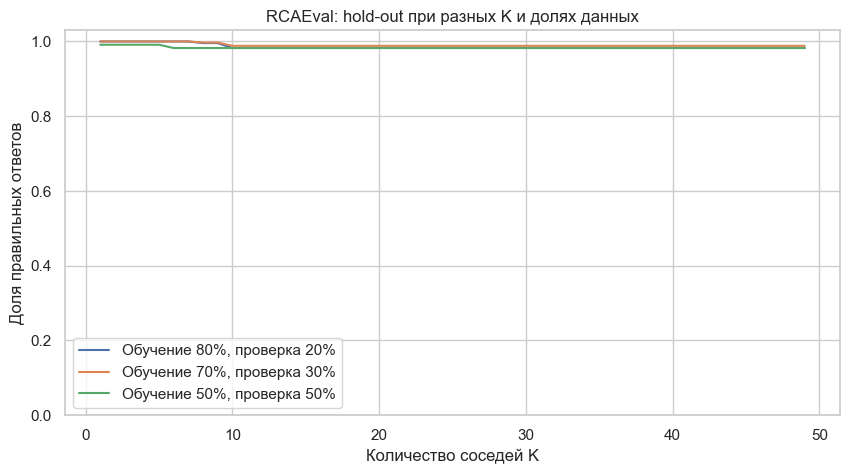

In [41]:
fig, ax = plt.subplots(figsize=(10, 5))
for share, part in rca_holdout.groupby('test_share'):
    ax.plot(part['K'], part['accuracy'], label=f'Обучение {1-share:.0%}, проверка {share:.0%}')
ax.set(title='RCAEval: hold-out при разных K и долях данных',
       xlabel='Количество соседей K', ylabel='Доля правильных ответов', ylim=(0, 1.03))
ax.legend()
save_show(fig, '07_rca_holdout.png')

Линии позволяют сравнить влияние K и количества обучающих строк. Когда линии совпадают, разные настройки дали одинаковую точность. Это возможно, если два периода хорошо различаются по выбранным метрикам. Такая оценка относится к этому эксперименту, а не ко всем будущим сбоям.

### 3.5. CV при разных K и числе частей — пункт 2.3
Сравниваем 3, 5 и 10 частей. В каждом варианте минутные участки сохраняются целиком. Число строк в частях может немного отличаться: делятся участки, а не отдельные строки. Каждая модель заново обучает и подготовку масштаба, и классификатор.

Вычисляем CV по минутным участкам RCAEval.

In [42]:
rca_cv = cv_table(Xr_dev, yr_dev, groups=gr_dev)
rca_cv.to_csv(REPORT / 'rca_cv.csv', index=False)

Показываем среднюю точность для всех K и числа частей.

In [43]:
display(rca_cv.pivot(index='K', columns='fold', values='accuracy').round(3))

fold,3,5,10
K,,,
1,0.952,0.954,0.938
2,0.967,0.962,0.954
3,0.967,0.962,0.954
4,0.967,0.962,0.954
5,0.967,0.962,0.954
6,0.967,0.962,0.954
7,0.967,0.962,0.954
8,0.967,0.962,0.954
9,0.967,0.962,0.954


Строим график ошибки CV для RCAEval.

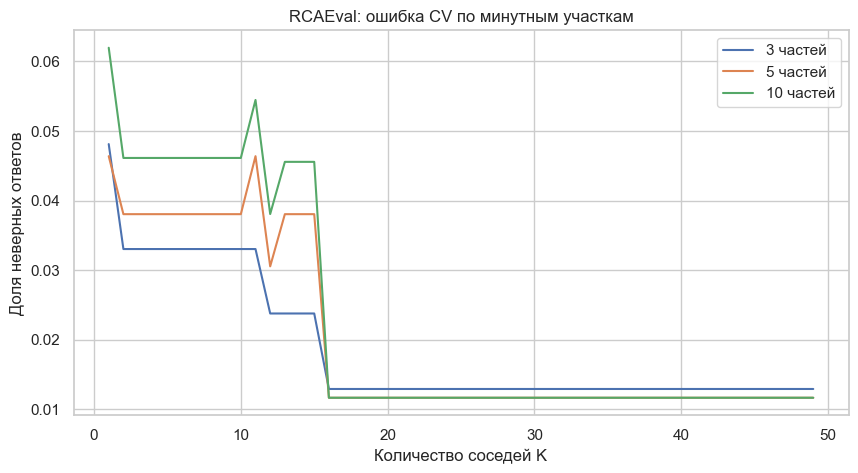

In [44]:
fig, ax = plt.subplots(figsize=(10, 5))
for fold, part in rca_cv.groupby('fold'):
    ax.plot(part['K'], part['error'], label=f'{fold} частей')
ax.set(title='RCAEval: ошибка CV по минутным участкам',
       xlabel='Количество соседей K', ylabel='Доля неверных ответов')
ax.legend()
save_show(fig, '08_rca_cv_error.png')

Низкая линия означает мало ошибок. Если ошибка равна нулю, модель правильно ответила на все проверочные строки в этих частях. Это не доказывает, что она найдёт любой новый сбой: все строки относятся к одному CPU-эксперименту. Число частей меняет состав обучения, поэтому сравниваем результаты по всем трём линиям.

На наших данных при K от 16 до 49 ошибка одинакова и ниже, чем при меньших K. Для пяти частей она составляет примерно 1,2%. Поэтому выбираем K = 16, а не увеличиваем число соседей без улучшения результата.

### 3.6. Лучшие K и обоснование выбора — пункт 2.4
Находим все K с наибольшей средней accuracy отдельно для 3, 5 и 10 частей. Итоговое K выбираем по **5 частям**. При равенстве выбираем наименьшее K. «Лучшее» здесь означает лучшее среди проверенных K для наших данных и способа проверки.

Находим лучшие значения K для RCAEval.

In [45]:
for fold, part in rca_cv.groupby('fold'):
    best = part.loc[part['accuracy'] == part['accuracy'].max(), 'K'].tolist()
    print(f'{fold} частей: лучшие K = {best}, accuracy = {part.accuracy.max():.3f}')
rca_primary = rca_cv.query('fold == 5')
rca_best_values = rca_primary.loc[rca_primary.accuracy == rca_primary.accuracy.max(), 'K'].tolist()
rca_best_k = min(rca_best_values)
print('Выбрано K =', rca_best_k)

3 частей: лучшие K = [16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49], accuracy = 0.987
5 частей: лучшие K = [16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49], accuracy = 0.988
10 частей: лучшие K = [16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49], accuracy = 0.988
Выбрано K = 16


Объясняем выбор K простыми словами.

In [46]:
display(Markdown(
    f'При проверке по 5 частям лучшая средняя accuracy — **{rca_primary.accuracy.max():.1%}**. '
    f'Такой результат дали **{len(rca_best_values)}** значений K. '
    f'Выбираем **K = {rca_best_k}**: это наименьшее число соседей среди лучших вариантов. '
    'Если лучшие значения совпали по качеству, таблица не позволяет объявить один из них единственно верным.'))

При проверке по 5 частям лучшая средняя accuracy — **98.8%**. Такой результат дали **34** значений K. Выбираем **K = 16**: это наименьшее число соседей среди лучших вариантов. Если лучшие значения совпали по качеству, таблица не позволяет объявить один из них единственно верным.

### 3.7. Модификации kNN
Сравниваем два способа голосования и два расстояния при выбранном K. `uniform` - каждый сосед имеет один голос; `distance` - более близкий сосед имеет больший вес. При `p = 2` используется обычное евклидово расстояние, при `p = 1` - сумма разностей признаков по модулю (манхэттенское расстояние).

Это дополнительное сравнение на данных подбора. Основную модель для итоговой проверки оставляем с обычным расстоянием и равными голосами, чтобы проверить именно правило выбора K из предыдущего пункта.

Сравниваем модификации по тем же пяти частям.

In [47]:
modification_rows = []
for weights in ['uniform', 'distance']:
    for p in [2, 1]:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        scores = cross_val_score(make_knn(rca_best_k, weights=weights, p=p),
                                 Xr_dev, yr_dev, groups=gr_dev, cv=cv, scoring='accuracy')
        modification_rows.append({'K': rca_best_k, 'weights': weights, 'p': p,
                                  'accuracy': scores.mean(), 'std': scores.std()})
modifications = pd.DataFrame(modification_rows)

Печатаем и сохраняем результаты сравнения модификаций.

In [48]:
display(modifications.round(4))
modifications.to_csv(REPORT / 'rca_modifications.csv', index=False)
plain_score = modifications.query('weights == "uniform" and p == 2').accuracy.iloc[0]
weighted_score = modifications.query('weights == "distance" and p == 2').accuracy.iloc[0]
display(Markdown(
    f'При K = {rca_best_k} обычное голосование с евклидовым расстоянием дало **{plain_score:.1%}**, '
    f'а голосование с весами по расстоянию — **{weighted_score:.1%}**. '
    'Сравнение относится к пяти частям CV на данных подбора.'))

,K,weights,p,accuracy,std
0,16,uniform,2,0.9883,0.0233
1,16,uniform,1,0.9883,0.0233
2,16,distance,2,0.9695,0.0341
3,16,distance,1,0.9778,0.0236


При K = 16 обычное голосование с евклидовым расстоянием дало **98.8%**, а голосование с весами по расстоянию — **96.9%**. Сравнение относится к пяти частям CV на данных подбора.

Сравниваем среднюю accuracy и разброс по частям. При K = 1 изменение веса голоса не меняет ответ: голосует один сосед. Разные расстояния могут выбрать разных соседей. Если все варианты дали одинаковый результат, в этом опыте преимущества одной модификации не видно.

### 3.8. Итоговая проверка и демонстрация классификатора
Обучаем выбранную модель на всех данных подбора и один раз проверяем на отложенных минутных участках. Эти участки не участвовали в поиске K.

Обучаем итоговую модель и получаем ответы на отложенных данных.

In [49]:
rca_model = make_knn(rca_best_k).fit(Xr_dev, yr_dev)
rca_prediction = rca_model.predict(Xr_test)
rca_accuracy = accuracy_score(yr_test, rca_prediction)
rca_balanced_accuracy = balanced_accuracy_score(yr_test, rca_prediction)
rca_errors = int((rca_prediction != yr_test).sum())
print(f'K = {rca_best_k}, итоговая accuracy = {rca_accuracy:.3f} ({rca_accuracy:.1%})')
print(f'Ошибок: {rca_errors} из {len(yr_test)}')
print(f'Средняя доля правильных ответов по двум классам: {rca_balanced_accuracy:.3f}')

K = 16, итоговая accuracy = 1.000 (100.0%)
Ошибок: 0 из 300
Средняя доля правильных ответов по двум классам: 1.000


Показываем ответы модели для нескольких ранее не использованных строк.

In [50]:
rca_demo = Xr_test.iloc[[0, len(Xr_test)//2, -1]].copy()
rca_demo['Настоящий период'] = yr_test.loc[rca_demo.index].map(dict(enumerate(rca_labels)))
rca_demo['Ответ модели'] = pd.Series(
    rca_model.predict(rca_demo[rca_features]), index=rca_demo.index).map(dict(enumerate(rca_labels)))
display(rca_demo)

,checkoutservice_cpu,checkoutservice_mem,checkoutservice_latency-50,checkoutservice_socket,Настоящий период,Ответ модели
0,0.215886,11702272.0,0.243182,9.0,До внесения,До внесения
630,0.461238,12001280.0,0.221875,9.0,До внесения,До внесения
1319,19.988612,16564224.0,0.317308,11.0,После внесения,После внесения


Строим таблицу правильных ответов и ошибок по двум периодам.

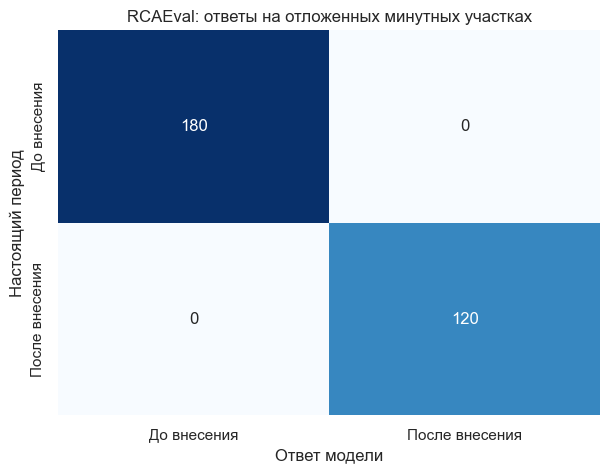

In [51]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(confusion_matrix(yr_test, rca_prediction, labels=[0, 1]), annot=True,
            fmt='d', cmap='Blues', cbar=False, xticklabels=rca_labels,
            yticklabels=rca_labels, ax=ax)
ax.set(title='RCAEval: ответы на отложенных минутных участках',
       xlabel='Ответ модели', ylabel='Настоящий период')
save_show(fig, '09_rca_confusion.png')

На диагонали стоят верные ответы «до» и «после». Вне диагонали стоят перепутанные периоды. Например, верхняя правая ячейка показывает строки до внесения, которые модель назвала строками после внесения. Это сравнение периодов эксперимента, а не подсчёт подтверждённых аварий.

На итоговой проверке верно определены все 180 строк периода до внесения и все 120 строк периода после внесения. Вне диагонали стоят нули: на этой подвыборке ошибок не было.

### 3.9. Наглядная граница между периодами
Как в учебном примере, строим отдельную модель по двум признакам: CPU и памяти. Цвет фона показывает её ответ для сочетаний этих показателей. Итоговая accuracy выше относится к основной модели с четырьмя признаками.

Обучаем отдельную модель для рисунка по CPU и памяти.

In [52]:
rca_plot_features = rca_features[:2]
rca_plot_model = make_knn(rca_best_k).fit(Xr_dev[rca_plot_features], yr_dev)

Строим области решений и отмечаем отложенные измерения.

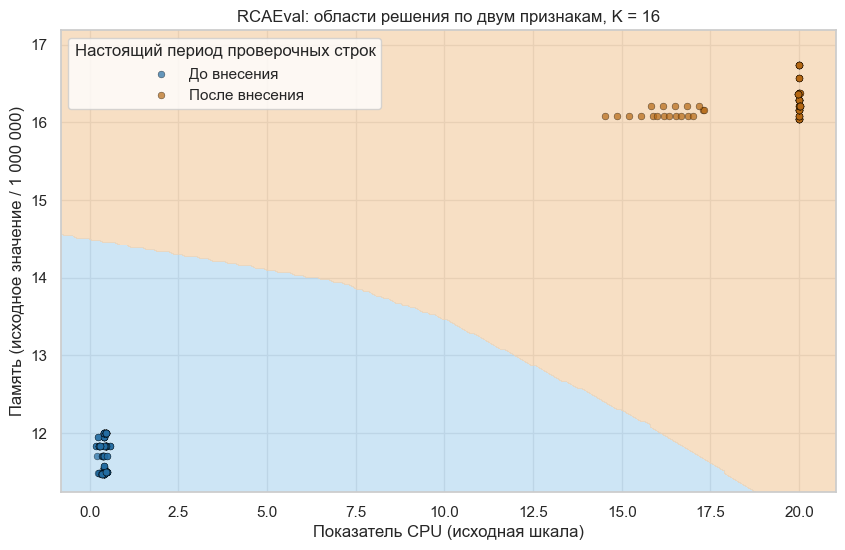

In [53]:
x = np.linspace(X_rca.iloc[:, 0].min() - 1, X_rca.iloc[:, 0].max() + 1, 200)
y = np.linspace(X_rca.iloc[:, 1].min() * 0.98, X_rca.iloc[:, 1].max() * 1.02, 200)
xx, yy = np.meshgrid(x, y)
grid_points = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=rca_plot_features)
regions = rca_plot_model.predict(grid_points).reshape(xx.shape)
fig, ax = plt.subplots(figsize=(10, 6))
ax.contourf(xx, yy / 1e6, regions, levels=[-0.5, 0.5, 1.5],
            cmap=ListedColormap(['#b8daf2', '#f5d2ac']), alpha=0.7)
for label, color in zip([0, 1], ['#246da2', '#b56813']):
    points = Xr_test.loc[yr_test == label]
    ax.scatter(points.iloc[:, 0], points.iloc[:, 1] / 1e6, color=color,
               edgecolor='black', linewidth=0.3, s=24, alpha=0.7, label=rca_labels[label])
ax.set(title=f'RCAEval: области решения по двум признакам, K = {rca_best_k}',
       xlabel='Показатель CPU (исходная шкала)', ylabel='Память (исходное значение / 1 000 000)')
ax.legend(title='Настоящий период проверочных строк')
save_show(fig, '10_rca_decision_regions.png')

Голубые и оранжевые точки показывают настоящие периоды измерений. CPU и память в этом сценарии помогают разделить группы. Граница фона показывает, как двухпризнаковая модель разделила бы новые сочетания показателей. Между группами мало наблюдений, поэтому по одному рисунку нельзя проверить ответы для всех промежуточных значений.

### 3.10. Формируем и сохраняем текст результата

Составляем простой текст о выполненном индивидуальном задании.

In [54]:
analysis_lines = [
    f'Использован прежний сценарий **{case}**: {len(df)} строк. Выбрано четыре числовых показателя без пропусков. Данные прочитаны с компьютера.',
    f'При заданном пользователем K = {K_USER} доля правильных ответов на внутренней проверке составила **{user_accuracy:.1%}**.',
    'Проверены K от 1 до 49, доли обучения 80%, 70% и 50%, а также CV по 3, 5 и 10 частям. В CV минутные участки сохранялись целиком.',
    f'По CV с 5 частями выбрано **K = {rca_best_k}**. Количество лучших значений K: {len(rca_best_values)}; выбрано наименьшее из них.',
    f'На итоговой проверке модель правильно определила период для **{len(yr_test)-rca_errors} из {len(yr_test)}** строк ({rca_accuracy:.1%}). Ошибок: **{rca_errors}**.',
    'Сравнил обычное и взвешенное голосование, а также два способа вычисления расстояний. Графики показали влияние K и то, как модель разделяет данные.',
    'Результат относится к определению периода одного CPU-эксперимента. Чтобы проверять новые сбои, нужны другие сценарии и отдельная проверка на них.'
]
analysis_text = '\n\n'.join(analysis_lines)
display(Markdown(analysis_text))
(REPORT / 'analysis.md').write_text('# Результаты индивидуального задания\n\n' + analysis_text, encoding='utf-8')

Использован прежний сценарий **re2ob_checkoutservice_cpu_1**: 1441 строк. Выбрано четыре числовых показателя без пропусков. Данные прочитаны с компьютера.

При заданном пользователем K = 3 доля правильных ответов на внутренней проверке составила **100.0%**.

Проверены K от 1 до 49, доли обучения 80%, 70% и 50%, а также CV по 3, 5 и 10 частям. В CV минутные участки сохранялись целиком.

По CV с 5 частями выбрано **K = 16**. Количество лучших значений K: 34; выбрано наименьшее из них.

На итоговой проверке модель правильно определила период для **300 из 300** строк (100.0%). Ошибок: **0**.

Сравнил обычное и взвешенное голосование, а также два способа вычисления расстояний. Графики показали влияние K и то, как модель разделяет данные.

Результат относится к определению периода одного CPU-эксперимента. Чтобы проверять новые сбои, нужны другие сценарии и отдельная проверка на них.

927

Сохраняем итоговые параметры, ответы и сведения об исходных файлах.

In [55]:
summary = {
    'case': case, 'features': rca_features, 'K_range': [1, 49], 'folds': FOLDS,
    'primary_fold': 5, 'random_state': SEED,
    'iris': {'best_K': iris_best_k, 'best_K_values': iris_best_values,
             'test_rows': len(yi_test), 'accuracy': iris_accuracy, 'errors': iris_errors},
    'rcaeval': {'best_K': rca_best_k, 'best_K_values': rca_best_values,
                'development_rows': len(yr_dev), 'test_rows': len(yr_test),
                'accuracy': rca_accuracy, 'balanced_accuracy': rca_balanced_accuracy,
                'errors': rca_errors, 'target': 'time >= inject_time',
                'split': 'minute groups, StratifiedGroupKFold'},
    'sources': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                for path in [iris_path, metrics_path, inject_path]},
    'figures': [path.name for path in sorted(FIGURES.glob('*.png'))]
}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
pd.DataFrame({'row': Xr_test.index, 'actual': yr_test.to_numpy(),
              'prediction': rca_prediction}).to_csv(REPORT / 'rca_test_predictions.csv', index=False)
print('Таблицы, результаты и графики сохранены в reports/lab03/')

Таблицы, результаты и графики сохранены в reports/lab03/
